In [1]:
# # ====================== RANDOM UNpython
# # ====================== RANDOM UNDERSAMPLE CLASS 0 ======================

# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# # ====================== READ CSV ======================

# data = pd.read_csv('/kaggle/input/competitions/santander-customer-transaction-prediction/train.csv')
# test_data = pd.read_csv('/kaggle/input/competitions/santander-customer-transaction-prediction/test.csv')

# X_all = data.drop(columns=['target', 'ID_code']).values
# y_all = data['target'].values
# X_kaggle_test = test_data.drop(columns=['ID_code']).values
# test_ids = test_data['ID_code'].values

# print(f"Original: {X_all.shape}")
# print(f"Class 0: {(y_all==0).sum()}  Class 1: {(y_all==1).sum()}")


# # ====================== SETTINGS ======================

# TARGET_CLASS0 = 60000

# # ====================== SEPARATE CLASSES ======================

# mask_c0 = (y_all == 0)
# mask_c1 = (y_all == 1)

# X_c0 = X_all[mask_c0]
# X_c1 = X_all[mask_c1]
# y_c1 = y_all[mask_c1]


# # ====================== RANDOM UNDERSAMPLE CLASS 0 ======================

# rng = np.random.RandomState(42)
# keep_idx = rng.choice(len(X_c0), size=TARGET_CLASS0, replace=False)
# X_c0_reduced = X_c0[keep_idx]

# print(f"\nReduced class 0: {X_c0_reduced.shape}")


# # ====================== REBUILD DATASET ======================

# X_all = np.vstack([X_c0_reduced, X_c1])
# y_all = np.concatenate([np.zeros(len(X_c0_reduced)), y_c1])

# shuffle_idx = rng.permutation(len(X_all))
# X_all = X_all[shuffle_idx]
# y_all = y_all[shuffle_idx]

# print(f"\nUndersampled dataset: {X_all.shape}")
# print(f"Class 0: {(y_all==0).sum()}  Class 1: {(y_all==1).sum()}")
# print(f"Positive rate: {y_all.mean():.5f}  (was {mask_c1.sum() / len(mask_c1):.5f})")


# # ====================== VERIFY ======================

# orig_mean = X_c0.mean(axis=0)
# new_mean = X_c0_reduced.mean(axis=0)
# orig_std = X_c0.std(axis=0) + 1e-8

# mean_dev = np.abs(new_mean - orig_mean) / orig_std
# std_ratio = (X_c0_reduced.std(axis=0) + 1e-8) / orig_std

# print(f"\n  Mean deviation: max={mean_dev.max():.4f}  mean={mean_dev.mean():.4f}")
# print(f"  Std ratio:      min={std_ratio.min():.4f}  max={std_ratio.max():.4f}  mean={std_ratio.mean():.4f}")


# # ====================== DIAGRAMS ======================

# fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# axes[0].scatter(orig_mean, new_mean, s=8, alpha=0.5)
# lims = [orig_mean.min(), orig_mean.max()]
# axes[0].plot(lims, lims, 'k--', alpha=0.3)
# axes[0].set_xlabel('Original mean')
# axes[0].set_ylabel('Reduced mean')
# axes[0].set_title('Feature means')

# axes[1].scatter(orig_std, X_c0_reduced.std(axis=0) + 1e-8, s=8, alpha=0.5)
# lims = [orig_std.min(), orig_std.max()]
# axes[1].plot(lims, lims, 'k--', alpha=0.3)
# axes[1].set_xlabel('Original std')
# axes[1].set_ylabel('Reduced std')
# axes[1].set_title('Feature stds')

# axes[2].hist(mean_dev, bins=50, color='steelblue', edgecolor='black', linewidth=0.5)
# axes[2].set_xlabel('Mean deviation (std units)')
# axes[2].set_ylabel('Feature count')
# axes[2].set_title('Per-feature mean deviation')

# plt.suptitle('Random Undersampling — Distribution Preservation', fontsize=13)
# plt.tight_layout()
# plt.show()

# print(f"\n  X_all: {X_all.shape}  y_all: {y_all.shape}")
# print(f"  X_kaggle_test: {X_kaggle_test.shape}  test_ids: {test_ids.shape}")
# print(f"  Ready for structural split.")

Full data: (200000, 200)
Kaggle test: (200000, 200)
Positive rate: 0.10049

===== Searching for best structural split =====

  Tried 159 seeds
  Best seed: 43
  Score:     0.02307
  Details:
    ratio_diff           = 0.00001
    feat_mean_diff       = 0.00314
    feat_std_diff        = 0.00222
    c0_diff              = 0.00345
    c1_diff              = 0.00972
    total                = 0.02307

===== LOCKED SPLIT =====
  X_train: (160000, 200)  y_train: (160000,)  (pos rate: 0.10049)
  X_test:  (40000, 200)  y_test:  (40000,)  (pos rate: 0.10050)
  All models use these variables. No moving parts.


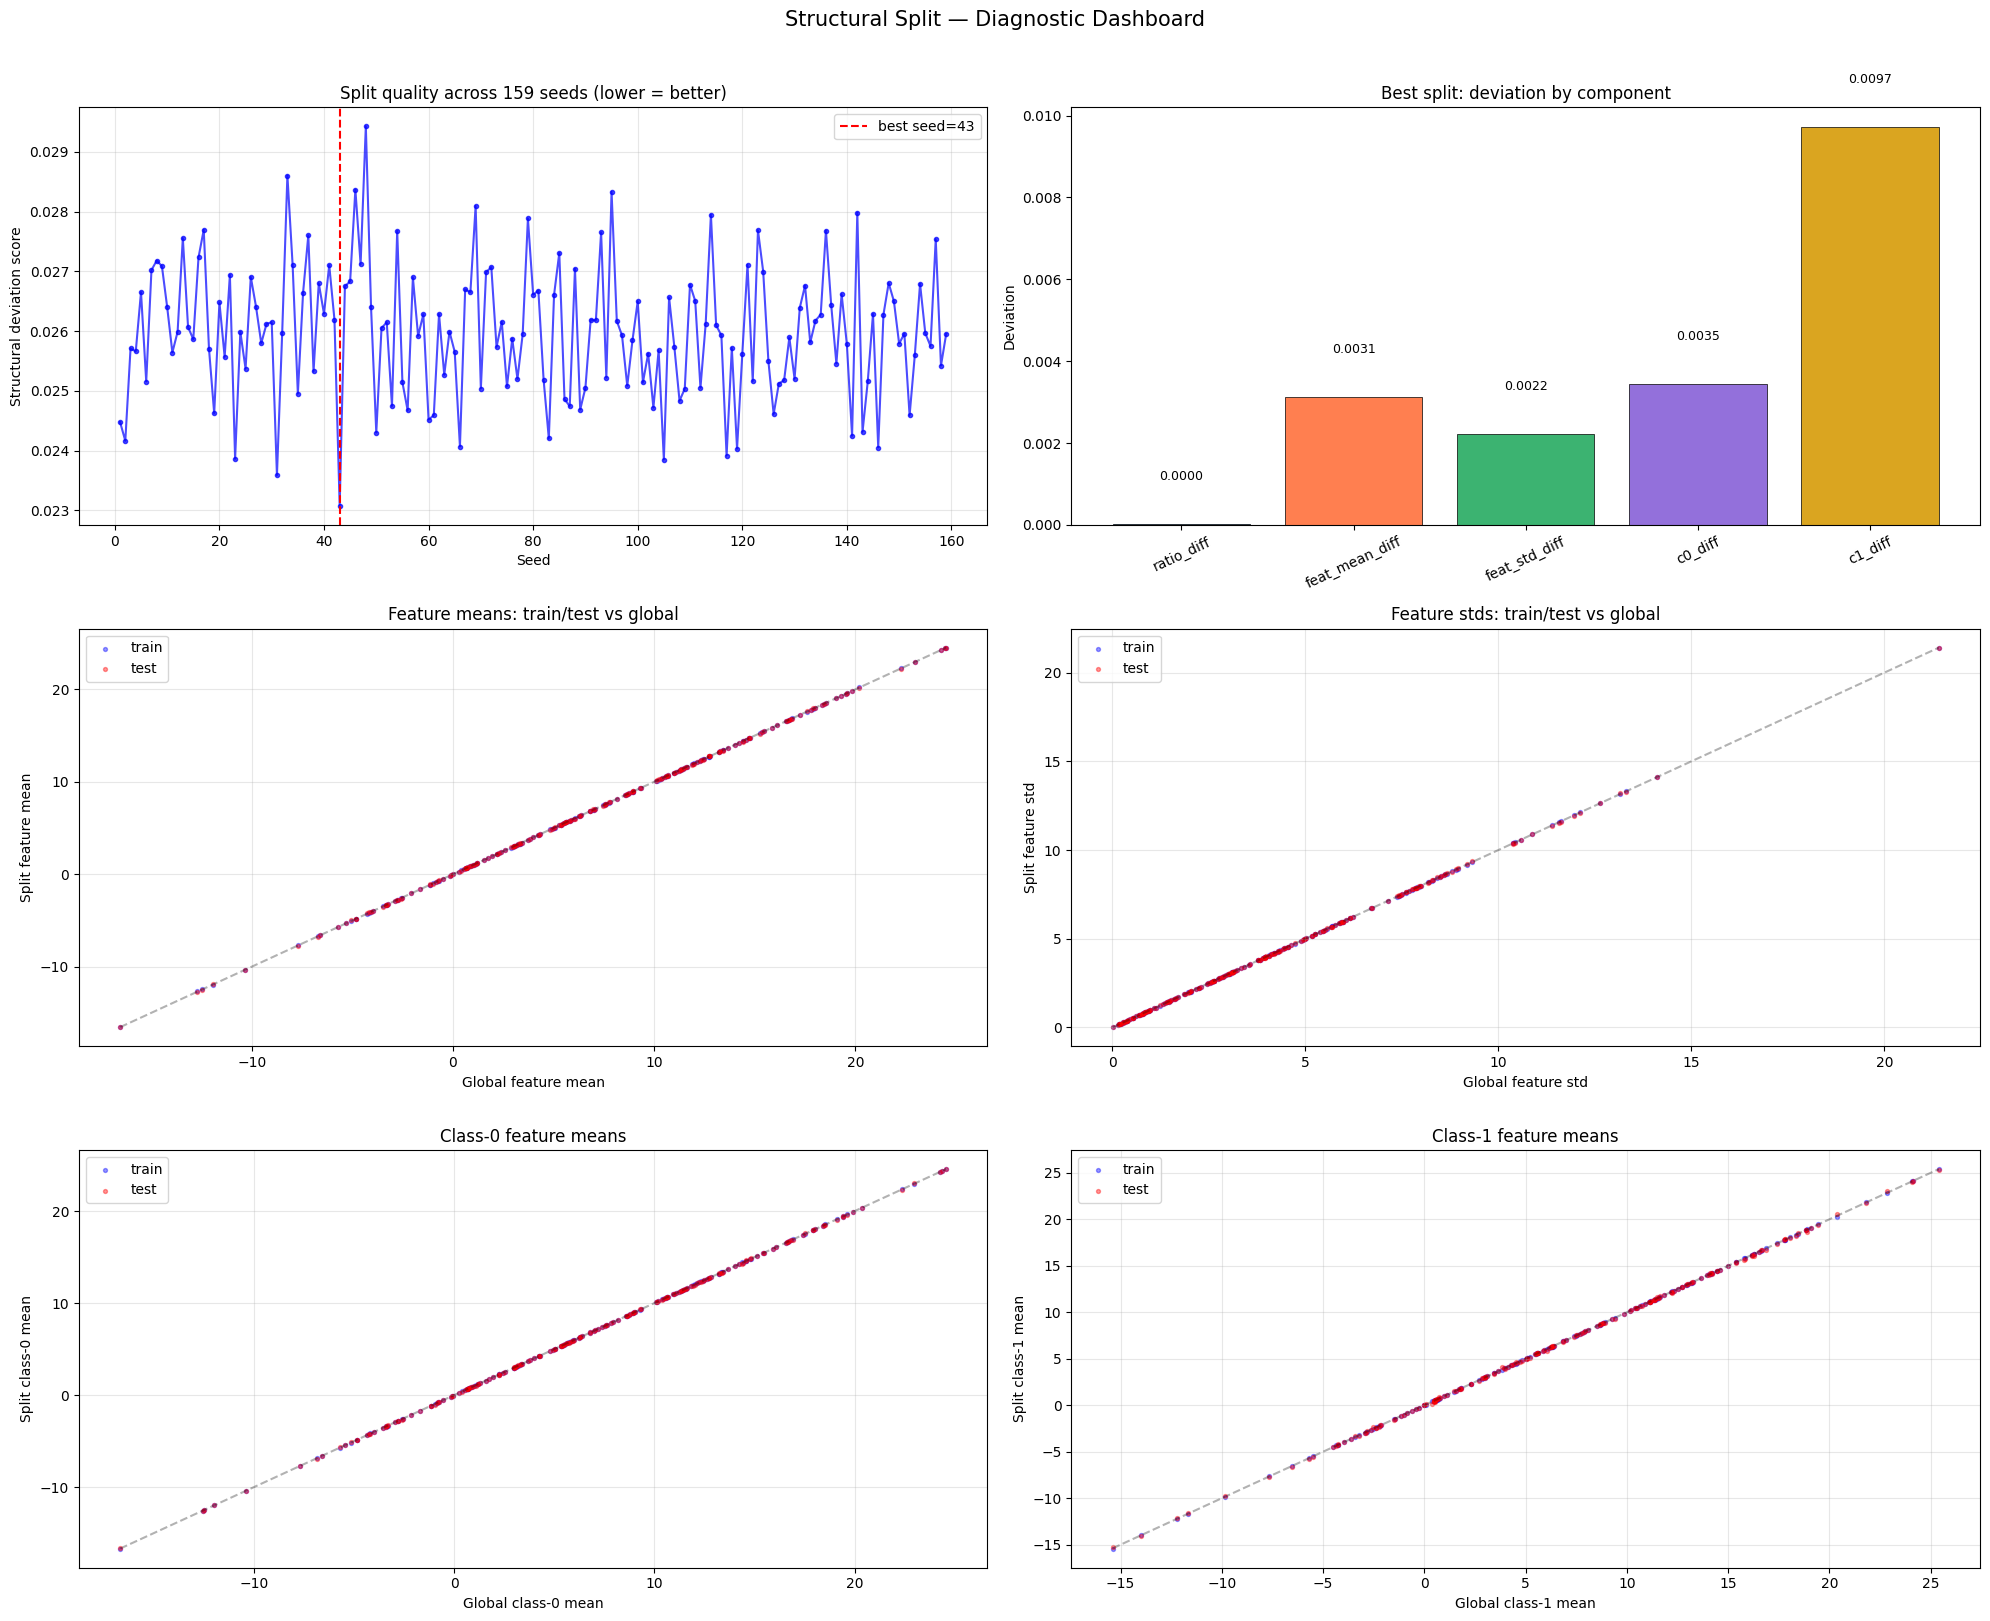

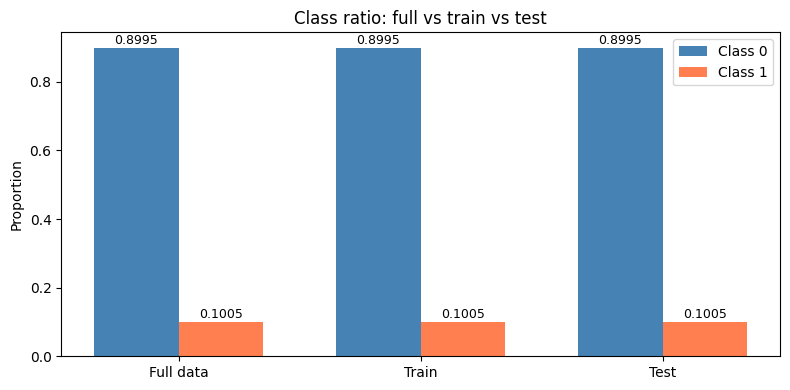

In [2]:
import numpy as np
import pandas as pdpython
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ====================== READ CSV ======================

data = pd.read_csv('/kaggle/input/competitions/santander-customer-transaction-prediction/train.csv')
test_data = pd.read_csv('/kaggle/input/competitions/santander-customer-transaction-prediction/test.csv')

X_all = data.drop(columns=['target', 'ID_code']).values
y_all = data['target'].values
X_kaggle_test = test_data.drop(columns=['ID_code']).values
test_ids = test_data['ID_code'].values

print(f"Full data: {X_all.shape}")
print(f"Kaggle test: {X_kaggle_test.shape}")
print(f"Positive rate: {y_all.mean():.5f}")


# ====================== FIND BEST STRUCTURAL SPLIT ======================

def score_split(X, y, X_tr, X_te, y_tr, y_te):
    """Score how well split preserves data structure. Lower = better."""
    global_mean = X.mean(axis=0)
    global_std = X.std(axis=0) + 1e-8

    ratio_diff = abs(y_tr.mean() - y_te.mean())

    tr_mean_diff = np.abs(X_tr.mean(axis=0) - global_mean) / global_std
    te_mean_diff = np.abs(X_te.mean(axis=0) - global_mean) / global_std
    feat_mean_diff = max(tr_mean_diff.mean(), te_mean_diff.mean())

    tr_std_ratio = np.abs(X_tr.std(axis=0) / global_std - 1)
    te_std_ratio = np.abs(X_te.std(axis=0) / global_std - 1)
    feat_std_diff = max(tr_std_ratio.mean(), te_std_ratio.mean())

    c0_global = X[y == 0].mean(axis=0)
    c1_global = X[y == 1].mean(axis=0)

    c0_tr_diff = np.abs(X_tr[y_tr == 0].mean(axis=0) - c0_global).mean() / global_std.mean()
    c0_te_diff = np.abs(X_te[y_te == 0].mean(axis=0) - c0_global).mean() / global_std.mean()
    c1_tr_diff = np.abs(X_tr[y_tr == 1].mean(axis=0) - c1_global).mean() / global_std.mean()
    c1_te_diff = np.abs(X_te[y_te == 1].mean(axis=0) - c1_global).mean() / global_std.mean()

    total = (ratio_diff * 100 + feat_mean_diff + feat_std_diff +
             c0_tr_diff + c0_te_diff + c1_tr_diff + c1_te_diff)

    details = {
        'ratio_diff': ratio_diff,
        'feat_mean_diff': feat_mean_diff,
        'feat_std_diff': feat_std_diff,
        'c0_diff': max(c0_tr_diff, c0_te_diff),
        'c1_diff': max(c1_tr_diff, c1_te_diff),
        'total': total
    }
    return total, details


print("\n===== Searching for best structural split =====")

best = {'score': float('inf')}
split_history = []

for seed in range(1, 160):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_all, y_all, test_size=0.2, random_state=seed, stratify=y_all
    )
    total, details = score_split(X_all, y_all, X_tr, X_te, y_tr, y_te)
    split_history.append({'seed': seed, **details})

    if total < best['score']:
        best = {
            'score': total, 'seed': seed, 'details': details,
            'X_tr': X_tr, 'X_te': X_te, 'y_tr': y_tr, 'y_te': y_te
        }

print(f"\n  Tried 159 seeds")
print(f"  Best seed: {best['seed']}")
print(f"  Score:     {best['score']:.5f}")
print(f"  Details:")
for k, v in best['details'].items():
    print(f"    {k:20s} = {v:.5f}")


# ====================== LOCK THE SPLIT ======================

X_train = best['X_tr']
X_test_split = best['X_te']
y_train = best['y_tr']
y_test = best['y_te']

# scale (fit on train only)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test_split)

print(f"\n===== LOCKED SPLIT =====")
print(f"  X_train: {X_train_sc.shape}  y_train: {y_train.shape}  (pos rate: {y_train.mean():.5f})")
print(f"  X_test:  {X_test_sc.shape}  y_test:  {y_test.shape}  (pos rate: {y_test.mean():.5f})")
print(f"  All models use these variables. No moving parts.")


# ====================== DIAGRAMS ======================

fig = plt.figure(figsize=(20, 16))

# ---- 1. Split quality across seeds ----
ax1 = fig.add_subplot(3, 2, 1)
df_hist = pd.DataFrame(split_history)
ax1.plot(df_hist['seed'], df_hist['total'], 'b-o', markersize=3, alpha=0.7)
ax1.axvline(x=best['seed'], color='red', linestyle='--', label=f"best seed={best['seed']}")
ax1.set_xlabel('Seed')
ax1.set_ylabel('Structural deviation score')
ax1.set_title('Split quality across 159 seeds (lower = better)')
ax1.legend()
ax1.grid(alpha=0.3)

# ---- 2. Score components for best split ----
ax2 = fig.add_subplot(3, 2, 2)
components = ['ratio_diff', 'feat_mean_diff', 'feat_std_diff', 'c0_diff', 'c1_diff']
values = [best['details'][c] for c in components]
colors = ['steelblue', 'coral', 'mediumseagreen', 'mediumpurple', 'goldenrod']
bars = ax2.bar(components, values, color=colors, edgecolor='black', linewidth=0.5)
ax2.set_ylabel('Deviation')
ax2.set_title('Best split: deviation by component')
for bar, val in zip(bars, values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
             f'{val:.4f}', ha='center', va='bottom', fontsize=9)
ax2.tick_params(axis='x', rotation=25)

# ---- 3. Feature means: train/test vs global ----
ax3 = fig.add_subplot(3, 2, 3)
global_mean = X_all.mean(axis=0)
ax3.scatter(global_mean, X_train.mean(axis=0), s=8, alpha=0.4, label='train', color='blue')
ax3.scatter(global_mean, X_test_split.mean(axis=0), s=8, alpha=0.4, label='test', color='red')
lims = [global_mean.min(), global_mean.max()]
ax3.plot(lims, lims, 'k--', alpha=0.3)
ax3.set_xlabel('Global feature mean')
ax3.set_ylabel('Split feature mean')
ax3.set_title('Feature means: train/test vs global')
ax3.legend()
ax3.grid(alpha=0.3)

# ---- 4. Feature stds: train/test vs global ----
ax4 = fig.add_subplot(3, 2, 4)
global_std = X_all.std(axis=0)
ax4.scatter(global_std, X_train.std(axis=0), s=8, alpha=0.4, label='train', color='blue')
ax4.scatter(global_std, X_test_split.std(axis=0), s=8, alpha=0.4, label='test', color='red')
lims = [global_std.min(), global_std.max()]
ax4.plot(lims, lims, 'k--', alpha=0.3)
ax4.set_xlabel('Global feature std')
ax4.set_ylabel('Split feature std')
ax4.set_title('Feature stds: train/test vs global')
ax4.legend()
ax4.grid(alpha=0.3)

# ---- 5. Class-conditional means: class 0 ----
ax5 = fig.add_subplot(3, 2, 5)
c0_global = X_all[y_all == 0].mean(axis=0)
c0_train = X_train[y_train == 0].mean(axis=0)
c0_test = X_test_split[y_test == 0].mean(axis=0)
ax5.scatter(c0_global, c0_train, s=8, alpha=0.4, label='train', color='blue')
ax5.scatter(c0_global, c0_test, s=8, alpha=0.4, label='test', color='red')
lims = [c0_global.min(), c0_global.max()]
ax5.plot(lims, lims, 'k--', alpha=0.3)
ax5.set_xlabel('Global class-0 mean')
ax5.set_ylabel('Split class-0 mean')
ax5.set_title('Class-0 feature means')
ax5.legend()
ax5.grid(alpha=0.3)

# ---- 6. Class-conditional means: class 1 ----
ax6 = fig.add_subplot(3, 2, 6)
c1_global = X_all[y_all == 1].mean(axis=0)
c1_train = X_train[y_train == 1].mean(axis=0)
c1_test = X_test_split[y_test == 1].mean(axis=0)
ax6.scatter(c1_global, c1_train, s=8, alpha=0.4, label='train', color='blue')
ax6.scatter(c1_global, c1_test, s=8, alpha=0.4, label='test', color='red')
lims = [c1_global.min(), c1_global.max()]
ax6.plot(lims, lims, 'k--', alpha=0.3)
ax6.set_xlabel('Global class-1 mean')
ax6.set_ylabel('Split class-1 mean')
ax6.set_title('Class-1 feature means')
ax6.legend()
ax6.grid(alpha=0.3)

plt.suptitle('Structural Split — Diagnostic Dashboard', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

# ---- extra: class ratio comparison ----
fig2, ax = plt.subplots(figsize=(8, 4))
labels = ['Full data', 'Train', 'Test']
pos_rates = [y_all.mean(), y_train.mean(), y_test.mean()]
neg_rates = [1 - y_all.mean(), 1 - y_train.mean(), 1 - y_test.mean()]

x = np.arange(len(labels))
width = 0.35
ax.bar(x - width/2, neg_rates, width, label='Class 0', color='steelblue')
ax.bar(x + width/2, pos_rates, width, label='Class 1', color='coral')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Proportion')
ax.set_title('Class ratio: full vs train vs test')
ax.legend()

for i, (n, p) in enumerate(zip(neg_rates, pos_rates)):
    ax.text(i - width/2, n + 0.01, f'{n:.4f}', ha='center', fontsize=9)
    ax.text(i + width/2, p + 0.01, f'{p:.4f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

In [3]:
# ====================== SLOW NB DATASET (7500 per class) ======================

import numpy as np
from sklearn.cluster import MiniBatchKMeans

TARGET_PER_CLASS = 10000

def cluster_balanced_subsample(X, n_target, n_clusters=50, seed=42):
    """K-means cluster-based proportional subsample. Preserves 200D sub-groups."""
    if len(X) <= n_target:
        return np.arange(len(X))
    km = MiniBatchKMeans(n_clusters=n_clusters, random_state=seed, batch_size=2048)
    labels = km.fit_predict(X)
    rng = np.random.RandomState(seed)
    selected = []
    for c in range(n_clusters):
        cluster_idx = np.where(labels == c)[0]
        if len(cluster_idx) == 0:
            continue
        n_keep = max(1, int(round(len(cluster_idx) * n_target / len(X))))
        n_keep = min(n_keep, len(cluster_idx))
        chosen = rng.choice(cluster_idx, size=n_keep, replace=False)
        selected.append(chosen)
    return np.concatenate(selected)

# separate classes from locked training set
rng = np.random.RandomState(42)
c0_idx = np.where(y_train == 0)[0]
c1_idx = np.where(y_train == 1)[0]

print(f"Training classes: class 0 = {len(c0_idx)}, class 1 = {len(c1_idx)}")

# class 0 (large): random sample to 7500
c0_selected = rng.choice(c0_idx, size=TARGET_PER_CLASS, replace=False)

# class 1 (small): cluster-based proportional sample to 7500
X_c1 = X_train_sc[c1_idx]
c1_local_idx = cluster_balanced_subsample(X_c1, n_target=TARGET_PER_CLASS, n_clusters=50, seed=42)
c1_selected = c1_idx[c1_local_idx]

print(f"  Class 0: {len(c0_selected)} (random from {len(c0_idx)})")
print(f"  Class 1: {len(c1_selected)} (cluster-based from {len(c1_idx)})")

# combine and shuffle
combined_idx = np.concatenate([c0_selected, c1_selected])
shuffle_idx = rng.permutation(len(combined_idx))
combined_idx = combined_idx[shuffle_idx]

X_train_slow = X_train_sc[combined_idx]
y_train_slow = y_train[combined_idx]

print(f"\n  X_train_slow: {X_train_slow.shape}")
print(f"  y_train_slow: {y_train_slow.shape}  (pos rate: {y_train_slow.mean():.5f})")

# verify class 1 sub-groups preserved
km_check = MiniBatchKMeans(n_clusters=50, random_state=42, batch_size=2048)
c1_labels_orig = km_check.fit_predict(X_train_sc[c1_idx])
c1_labels_sub = km_check.predict(X_train_slow[y_train_slow == 1])
orig_counts = np.bincount(c1_labels_orig, minlength=50)
sub_counts = np.bincount(c1_labels_sub, minlength=50)
ratio = sub_counts / np.maximum(orig_counts, 1)
print(f"\n  Class 1 sub-group check (50 clusters):")
print(f"    ratio min={ratio.min():.3f}  max={ratio.max():.3f}  mean={ratio.mean():.3f}")
print(f"    clusters with 0 samples: {(sub_counts == 0).sum()}")

Training classes: class 0 = 143922, class 1 = 16078
  Class 0: 10000 (random from 143922)
  Class 1: 10000 (cluster-based from 16078)

  X_train_slow: (20000, 200)
  y_train_slow: (20000,)  (pos rate: 0.50000)

  Class 1 sub-group check (50 clusters):
    ratio min=0.618  max=1.000  mean=0.631
    clusters with 0 samples: 0


In [4]:
# # ====================== TEST 5 NAIVE BAYES VARIANTS ======================

# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import time
# import warnings
# from sklearn.naive_bayes import GaussianNB
# from sklearn.neighbors import KernelDensity
# from sklearn.metrics import roc_curve, auc, accuracy_score, f1_score, precision_score, recall_score
# from scipy.stats import t as student_t
# from scipy.stats import gennorm

# print(f"Full data (fast NBs):    X_train_sc={X_train_sc.shape}  y_train={y_train.shape}")
# print(f"Small data (slow NBs):   X_train_slow={X_train_slow.shape}  y_train_slow={y_train_slow.shape}")
# print(f"Test:                    X_test_sc={X_test_sc.shape}  y_test={y_test.shape}")


# # ====================== HELPERS ======================

# def best_threshold_metrics(y_true, scores):
#     fpr, tpr, thr_arr = roc_curve(y_true, scores)
#     J = tpr - fpr
#     idx = int(np.argmax(J))
#     thr = thr_arr[idx]
#     y_pred = (scores >= thr).astype(int)
#     return {
#         'best_thr': thr,
#         'auc_binary': (1 + tpr[idx] - fpr[idx]) / 2,
#         'acc': accuracy_score(y_true, y_pred),
#         'f1': f1_score(y_true, y_pred),
#         'prec': precision_score(y_true, y_pred),
#         'rec': recall_score(y_true, y_pred),
#     }


# # ====================== 1. GNB (fast — full data) ======================

# print("\n" + "=" * 70)
# print("1. GNB (Gaussian Naive Bayes) — full data")
# print("=" * 70)

# t0 = time.time()
# gnb = GaussianNB(var_smoothing=1e-6)
# gnb.fit(X_train_sc, y_train)
# gnb_scores = gnb.predict_proba(X_test_sc)[:, 1]
# gnb_time = time.time() - t0

# fpr, tpr, _ = roc_curve(y_test, gnb_scores)
# gnb_auc = auc(fpr, tpr)
# gnb_m = best_threshold_metrics(y_test, gnb_scores)
# print(f"  AUC_prob={gnb_auc:.4f}  AUC_bin={gnb_m['auc_binary']:.4f}  time={gnb_time:.1f}s")


# # ====================== KDE-NB CLASS ======================

# class KDENaiveBayes:
#     def __init__(self, kernel='gaussian', bandwidth=0.5, max_train=15000, seed=42):
#         self.kernel = kernel
#         self.bandwidth = bandwidth
#         self.max_train = max_train
#         self.seed = seed

#     def fit(self, X, y):
#         self.classes_ = np.unique(y)
#         self.priors_ = np.array([max((y == c).mean(), 1e-10) for c in self.classes_])
#         self.kdes_ = {}
#         rng = np.random.RandomState(self.seed)
#         for c in self.classes_:
#             Xc = X[y == c]
#             if len(Xc) > self.max_train:
#                 idx = rng.choice(len(Xc), self.max_train, replace=False)
#                 Xc = Xc[idx]
#             self.kdes_[c] = []
#             for j in range(X.shape[1]):
#                 kde = KernelDensity(kernel=self.kernel, bandwidth=self.bandwidth)
#                 kde.fit(Xc[:, j].reshape(-1, 1))
#                 self.kdes_[c].append(kde)
#         return self

#     def predict_proba(self, X):
#         n = len(X)
#         log_joint = np.zeros((n, len(self.classes_)))
#         for ci, c in enumerate(self.classes_):
#             for j in range(X.shape[1]):
#                 log_joint[:, ci] += self.kdes_[c][j].score_samples(X[:, j].reshape(-1, 1))
#             log_joint[:, ci] += np.log(self.priors_[ci])
#         log_joint = np.nan_to_num(log_joint, nan=-1e10, posinf=1e10, neginf=-1e10)
#         log_joint -= log_joint.max(axis=1, keepdims=True)
#         probs = np.exp(log_joint)
#         probs /= np.clip(probs.sum(axis=1, keepdims=True), 1e-10, None)
#         return probs


# # ====================== 2. KDE-NB (RBF) (fast — full data) ======================

# print("\n" + "=" * 70)
# print("2. KDE-NB (RBF kernel) — full data")
# print("=" * 70)

# t0 = time.time()
# kde_rbf = KDENaiveBayes(kernel='gaussian', bandwidth=0.5, max_train=20000)
# kde_rbf.fit(X_train_sc, y_train)
# kde_rbf_scores = kde_rbf.predict_proba(X_test_sc)[:, 1]
# kde_rbf_time = time.time() - t0

# fpr, tpr, _ = roc_curve(y_test, kde_rbf_scores)
# kde_rbf_auc = auc(fpr, tpr)
# kde_rbf_m = best_threshold_metrics(y_test, kde_rbf_scores)
# print(f"  AUC_prob={kde_rbf_auc:.4f}  AUC_bin={kde_rbf_m['auc_binary']:.4f}  time={kde_rbf_time:.1f}s")


# # ====================== 3. KDE-NB (tophat) (fast — full data) ======================

# print("\n" + "=" * 70)
# print("3. KDE-NB (tophat kernel) — full data")
# print("=" * 70)

# t0 = time.time()
# kde_tophat = KDENaiveBayes(kernel='tophat', bandwidth=0.5, max_train=20000)
# kde_tophat.fit(X_train_sc, y_train)
# kde_tophat_scores = kde_tophat.predict_proba(X_test_sc)[:, 1]
# kde_tophat_time = time.time() - t0

# fpr, tpr, _ = roc_curve(y_test, kde_tophat_scores)
# kde_tophat_auc = auc(fpr, tpr)
# kde_tophat_m = best_threshold_metrics(y_test, kde_tophat_scores)
# print(f"  AUC_prob={kde_tophat_auc:.4f}  AUC_bin={kde_tophat_m['auc_binary']:.4f}  time={kde_tophat_time:.1f}s")


# # ====================== 4. Student-t NB (slow — 15k balanced) ======================

# class StudentTNB:
#     def __init__(self, seed=42):
#         self.seed = seed

#     def fit(self, X, y):
#         self.classes_ = np.unique(y)
#         self.priors_ = np.array([max((y == c).mean(), 1e-10) for c in self.classes_])
#         self.params_ = {}
#         for c in self.classes_:
#             Xc = X[y == c]
#             self.params_[c] = []
#             for j in range(X.shape[1]):
#                 try:
#                     with warnings.catch_warnings():
#                         warnings.simplefilter('ignore')
#                         df, loc, scale = student_t.fit(Xc[:, j])
#                     df = max(df, 1.01)
#                     scale = max(scale, 1e-6)
#                 except Exception:
#                     df = 1e10
#                     loc = Xc[:, j].mean()
#                     scale = max(Xc[:, j].std(), 1e-6)
#                 self.params_[c].append((df, loc, scale))
#         return self

#     def predict_proba(self, X):
#         n = len(X)
#         log_joint = np.zeros((n, len(self.classes_)))
#         for ci, c in enumerate(self.classes_):
#             for j in range(X.shape[1]):
#                 df, loc, scale = self.params_[c][j]
#                 log_joint[:, ci] += student_t.logpdf(X[:, j], df, loc=loc, scale=scale)
#             log_joint[:, ci] += np.log(self.priors_[ci])
#         log_joint = np.nan_to_num(log_joint, nan=-1e10, posinf=1e10, neginf=-1e10)
#         log_joint -= log_joint.max(axis=1, keepdims=True)
#         probs = np.exp(log_joint)
#         probs /= np.clip(probs.sum(axis=1, keepdims=True), 1e-10, None)
#         return probs


# print("\n" + "=" * 70)
# print("4. Student-t Naive Bayes — 15k balanced")
# print("=" * 70)

# t0 = time.time()
# tnb = StudentTNB()
# tnb.fit(X_train_slow, y_train_slow)
# tnb_scores = tnb.predict_proba(X_test_sc)[:, 1]
# tnb_time = time.time() - t0

# fpr, tpr, _ = roc_curve(y_test, tnb_scores)
# tnb_auc = auc(fpr, tpr)
# tnb_m = best_threshold_metrics(y_test, tnb_scores)
# print(f"  AUC_prob={tnb_auc:.4f}  AUC_bin={tnb_m['auc_binary']:.4f}  time={tnb_time:.1f}s")


# # ====================== 5. Generalized Gaussian NB (slow — 15k balanced) ======================

# class GeneralizedGaussianNB:
#     def __init__(self, seed=42):
#         self.seed = seed

#     def fit(self, X, y):
#         self.classes_ = np.unique(y)
#         self.priors_ = np.array([max((y == c).mean(), 1e-10) for c in self.classes_])
#         self.params_ = {}
#         for c in self.classes_:
#             Xc = X[y == c]
#             self.params_[c] = []
#             for j in range(X.shape[1]):
#                 try:
#                     with warnings.catch_warnings():
#                         warnings.simplefilter('ignore')
#                         p, loc, scale = gennorm.fit(Xc[:, j])
#                     p = max(p, 0.1)
#                     scale = max(scale, 1e-6)
#                 except Exception:
#                     p = 2.0
#                     loc = Xc[:, j].mean()
#                     scale = max(Xc[:, j].std(), 1e-6)
#                 self.params_[c].append((p, loc, scale))
#         return self

#     def predict_proba(self, X):
#         n = len(X)
#         log_joint = np.zeros((n, len(self.classes_)))
#         for ci, c in enumerate(self.classes_):
#             for j in range(X.shape[1]):
#                 p, loc, scale = self.params_[c][j]
#                 log_joint[:, ci] += gennorm.logpdf(X[:, j], p, loc=loc, scale=scale)
#             log_joint[:, ci] += np.log(self.priors_[ci])
#         log_joint = np.nan_to_num(log_joint, nan=-1e10, posinf=1e10, neginf=-1e10)
#         log_joint -= log_joint.max(axis=1, keepdims=True)
#         probs = np.exp(log_joint)
#         probs /= np.clip(probs.sum(axis=1, keepdims=True), 1e-10, None)
#         return probs


# print("\n" + "=" * 70)
# print("5. Generalized Gaussian Naive Bayes — 15k balanced")
# print("=" * 70)

# t0 = time.time()
# ggnb = GeneralizedGaussianNB()
# ggnb.fit(X_train_slow, y_train_slow)
# ggnb_scores = ggnb.predict_proba(X_test_sc)[:, 1]
# ggnb_time = time.time() - t0

# fpr, tpr, _ = roc_curve(y_test, ggnb_scores)
# ggnb_auc = auc(fpr, tpr)
# ggnb_m = best_threshold_metrics(y_test, ggnb_scores)
# print(f"  AUC_prob={ggnb_auc:.4f}  AUC_bin={ggnb_m['auc_binary']:.4f}  time={ggnb_time:.1f}s")


# # ====================== SUMMARY ======================

# results = [
#     {'model': 'GNB (Gaussian)',   'data': 'full',    'auc_prob': gnb_auc,        'time': gnb_time,        **gnb_m},
#     {'model': 'KDE-NB (RBF)',     'data': 'full',    'auc_prob': kde_rbf_auc,    'time': kde_rbf_time,    **kde_rbf_m},
#     {'model': 'KDE-NB (tophat)',  'data': 'full',    'auc_prob': kde_tophat_auc, 'time': kde_tophat_time, **kde_tophat_m},
#     {'model': 'Student-t NB',     'data': '15k bal', 'auc_prob': tnb_auc,         'time': tnb_time,         **tnb_m},
#     {'model': 'GenGaussian NB',   'data': '15k bal', 'auc_prob': ggnb_auc,        'time': ggnb_time,        **ggnb_m},
# ]

# df_res = pd.DataFrame(results).sort_values('auc_binary', ascending=False)

# print(f"\n{'='*105}")
# print("5 NAIVE BAYES VARIANTS — ranked by binary AUC")
# print(f"{'='*105}")
# print(df_res[['model', 'data', 'auc_prob', 'auc_binary', 'best_thr', 'f1', 'prec', 'rec', 'time']]
#       .to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# print(f"\n  GNB reference: AUC_bin=0.8075 (full data), ~0.810 (undersampled)")


# # ====================== ROC PLOT ======================

# plt.figure(figsize=(10, 8))
# colors = {
#     'GNB (Gaussian)': 'red',
#     'KDE-NB (RBF)': 'tab:blue',
#     'KDE-NB (tophat)': 'tab:green',
#     'Student-t NB': 'tab:orange',
#     'GenGaussian NB': 'tab:purple',
# }
# score_dict = {
#     'GNB (Gaussian)': gnb_scores,
#     'KDE-NB (RBF)': kde_rbf_scores,
#     'KDE-NB (tophat)': kde_tophat_scores,
#     'Student-t NB': tnb_scores,
#     'GenGaussian NB': ggnb_scores,
# }

# for name, scores in score_dict.items():
#     fpr, tpr, _ = roc_curve(y_test, scores)
#     roc_auc = auc(fpr, tpr)
#     lw = 2.5 if name == 'GNB (Gaussian)' else 1.5
#     plt.plot(fpr, tpr, color=colors[name], lw=lw,
#              label=f'{name} (AUC={roc_auc:.3f})')

# plt.plot([0, 1], [0, 1], 'k:', label='chance')
# plt.xlabel('False Positive Rate')
# plt.ylabel('True Positive Rate')
# plt.title('ROC — 5 Naive Bayes Variants')
# plt.legend(loc='lower right', fontsize=9)
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()


# # ====================== BINARY AUC DIAGRAM ======================

# plt.figure(figsize=(10, 8))

# for _, row in df_res.iterrows():
#     tpr_bin = row['rec']
#     fpr_bin = tpr_bin - (2 * row['auc_binary'] - 1)
#     color = colors[row['model']]
#     lw = 2.5 if row['model'] == 'GNB (Gaussian)' else 1.5
#     plt.plot([0, fpr_bin, 1], [0, tpr_bin, 1], '-o', color=color,
#              lw=lw, alpha=0.7,
#              label=f"{row['model']} (AUC_bin={row['auc_binary']:.3f})")

# plt.plot([0, 1], [0, 1], 'k:', label='chance')
# plt.xlabel('False Positive Rate')
# plt.ylabel('True Positive Rate')
# plt.title("Binary AUC (Youden's J) — 5 NB Variants")
# plt.legend(loc='lower right', fontsize=9)
# plt.xlim(-0.02, 1.02)
# plt.ylim(-0.02, 1.02)
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

In [5]:
# # ====================== RBF vs RQ — SIMPLE, FIXED ======================

# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import time
# import torch
# import torch.nn as nn
# from torch.utils.data import DataLoader, TensorDataset
# from sklearn.metrics import roc_curve, auc, accuracy_score, f1_score, precision_score, recall_score

# print(f"X_train_sc: {X_train_sc.shape}  y_train: {y_train.shape}")
# print(f"X_test_sc:  {X_test_sc.shape}  y_test: {y_test.shape}")


# def best_threshold_metrics(y_true, scores):
#     fpr, tpr, thr_arr = roc_curve(y_true, scores)
#     J = tpr - fpr
#     idx = int(np.argmax(J))
#     thr = thr_arr[idx]
#     y_pred = (scores >= thr).astype(int)
#     return {
#         'best_thr': thr,
#         'auc_binary': (1 + tpr[idx] - fpr[idx]) / 2,
#         'acc': accuracy_score(y_true, y_pred),
#         'f1': f1_score(y_true, y_pred),
#         'prec': precision_score(y_true, y_pred),
#         'rec': recall_score(y_true, y_pred),
#     }


# # ====================== LAYERS ======================

# class RBFLayer(nn.Module):
#     def __init__(self, n_input, n_rbf, X_init):
#         super().__init__()
#         idx = np.random.RandomState(42).choice(len(X_init), n_rbf, replace=False)
#         self.centers = nn.Parameter(torch.FloatTensor(X_init[idx]))
#         with torch.no_grad():
#             d = torch.cdist(self.centers, self.centers)
#             med = d.median().item()
#         self.log_sigma = nn.Parameter(torch.ones(n_rbf) * np.log(med / 2 + 1e-8))

#     def forward(self, x):
#         d2 = torch.cdist(x, self.centers, p=2).pow(2)
#         sigma2 = torch.exp(2 * self.log_sigma).unsqueeze(0)
#         return torch.exp(-d2 / (2 * sigma2))


# class RQLayer(nn.Module):
#     def __init__(self, n_input, n_rq, X_init, alpha_init=1.5):
#         super().__init__()
#         idx = np.random.RandomState(42).choice(len(X_init), n_rq, replace=False)
#         self.centers = nn.Parameter(torch.FloatTensor(X_init[idx]))
#         with torch.no_grad():
#             d = torch.cdist(self.centers, self.centers)
#             med = d.median().item()
#         self.log_sigma = nn.Parameter(torch.ones(n_rq) * np.log(med / 2 + 1e-8))
#         self.log_alpha = nn.Parameter(torch.ones(n_rq) * np.log(alpha_init))

#     def forward(self, x):
#         d2 = torch.cdist(x, self.centers, p=2).pow(2)
#         sigma2 = torch.exp(2 * self.log_sigma).unsqueeze(0)
#         alpha = torch.exp(self.log_alpha).unsqueeze(0)
#         return (1 + d2 / (2 * alpha * sigma2)).pow(-alpha)


# # ====================== MODELS (keep them simple) ======================

# class RBFClassifier(nn.Module):
#     """RBF -> Linear. Nothing else."""
#     def __init__(self, n_input, n_rbf, X_init):
#         super().__init__()
#         self.bump = RBFLayer(n_input, n_rbf, X_init)
#         self.output = nn.Linear(n_rbf, 1)

#     def forward(self, x):
#         return self.output(self.bump(x)).squeeze(-1)


# class RQClassifier(nn.Module):
#     """RQ -> Linear. Nothing else."""
#     def __init__(self, n_input, n_rq, X_init):
#         super().__init__()
#         self.bump = RQLayer(n_input, n_rq, X_init)
#         self.output = nn.Linear(n_rq, 1)

#     def forward(self, x):
#         return self.output(self.bump(x)).squeeze(-1)


# # ====================== TRAINING (with early stopping) ======================

# def train_nn(model, X_tr, y_tr, X_te, y_te, epochs=200, lr=0.001,
#              batch_size=2048, patience=15):
#     torch.manual_seed(42)
#     X_tr_t = torch.FloatTensor(X_tr)
#     y_tr_t = torch.FloatTensor(y_tr)
#     X_te_t = torch.FloatTensor(X_te)

#     optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
#     scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
#         optimizer, mode='max', factor=0.5, patience=5)
#     criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([9.0]))
#     train_dl = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=batch_size, shuffle=True)

#     best_auc = 0
#     best_state = None
#     no_improve = 0

#     t0 = time.time()
#     for epoch in range(epochs):
#         model.train()
#         epoch_loss = 0
#         for Xb, yb in train_dl:
#             optimizer.zero_grad()
#             loss = criterion(model(Xb), yb)
#             loss.backward()
#             optimizer.step()
#             epoch_loss += loss.item()

#         # evaluate on test for early stopping
#         model.eval()
#         with torch.no_grad():
#             val_scores = torch.sigmoid(model(X_te_t)).numpy()
#         fpr, tpr, _ = roc_curve(y_te, val_scores)
#         val_auc = auc(fpr, tpr)

#         scheduler.step(val_auc)

#         if val_auc > best_auc:
#             best_auc = val_auc
#             best_state = {k: v.clone() for k, v in model.state_dict().items()}
#             no_improve = 0
#         else:
#             no_improve += 1

#         if (epoch + 1) % 20 == 0:
#             print(f"    epoch {epoch+1}: loss={epoch_loss/len(train_dl):.4f}  "
#                   f"val_auc={val_auc:.4f}  best={best_auc:.4f}")

#         if no_improve >= patience:
#             print(f"    early stopping at epoch {epoch+1}")
#             break

#     # restore best model
#     if best_state is not None:
#         model.load_state_dict(best_state)

#     model.eval()
#     with torch.no_grad():
#         test_scores = torch.sigmoid(model(X_te_t)).numpy()

#     train_time = time.time() - t0

#     fpr, tpr, _ = roc_curve(y_te, test_scores)
#     auc_prob = auc(fpr, tpr)
#     m = best_threshold_metrics(y_te, test_scores)

#     print(f"  AUC_prob={auc_prob:.4f}  AUC_bin={m['auc_binary']:.4f}  "
#           f"f1={m['f1']:.4f}  time={train_time:.1f}s")

#     return test_scores, auc_prob, m, train_time


# # ====================== TEST 2 MODELS ======================

# configs = [
#     ('RBF (simple)',  RBFClassifier(X_train_sc.shape[1], 256, X_train_sc)),
#     ('RQ (simple)',   RQClassifier(X_train_sc.shape[1], 256, X_train_sc)),
# ]

# results = []

# for name, model in configs:
#     print(f"\n{'='*70}")
#     print(f"  {name}")
#     print(f"{'='*70}")
#     scores, auc_prob, m, t = train_nn(model, X_train_sc, y_train,
#                                        X_test_sc, y_test,
#                                        epochs=200, lr=0.001)
#     results.append({'model': name, 'auc_prob': auc_prob, 'time': t,
#                     'scores': scores, **m})


# # ====================== SUMMARY ======================

# df_res = pd.DataFrame([{k: v for k, v in r.items() if k != 'scores'}
#                         for r in results]).sort_values('auc_binary', ascending=False)

# print(f"\n{'='*85}")
# print("RBF vs RQ — simple architecture, trained to convergence")
# print(f"{'='*85}")
# print(df_res.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
# print(f"\n  GNB reference: AUC_prob=0.8887  AUC_bin=0.8102")


# # ====================== PLOTS ======================

# plt.figure(figsize=(10, 8))
# colors = {'RBF (simple)': 'tab:blue', 'RQ (simple)': 'tab:orange'}
# for r in results:
#     fpr, tpr, _ = roc_curve(y_test, r['scores'])
#     plt.plot(fpr, tpr, color=colors[r['model']], lw=2,
#              label=f"{r['model']} (AUC={r['auc_prob']:.3f})")
# plt.plot([0, 1], [0, 1], 'k:', label='chance')
# plt.xlabel('False Positive Rate')
# plt.ylabel('True Positive Rate')
# plt.title('ROC — RBF vs RQ (simple, trained to convergence)')
# plt.legend(loc='lower right')
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

X_train_sc: (160000, 200)  y_train: (160000,)
X_test_sc:  (40000, 200)  y_test: (40000,)
pos_weight = 9.0

  RBF (old)
    epoch 10: loss=0.7474
    epoch 20: loss=0.6112
    epoch 30: loss=0.6992
    epoch 40: loss=0.8180
    epoch 50: loss=0.5811
  AUC_prob=0.8823  AUC_bin=0.8006  f1=0.4432  time=138.7s

  RQ
    epoch 10: loss=0.9342
    epoch 20: loss=0.6327
    epoch 30: loss=0.7084
    epoch 40: loss=0.8201
    epoch 50: loss=0.5846
  AUC_prob=0.8823  AUC_bin=0.8012  f1=0.4616  time=173.4s

  RBF + Dropout
    epoch 10: loss=0.9395
    epoch 20: loss=0.9189
    epoch 30: loss=0.9025
    epoch 40: loss=0.8905
    epoch 50: loss=1.0697
  AUC_prob=0.8821  AUC_bin=0.8015  f1=0.4601  time=171.9s

  RBF + BatchNorm
    epoch 10: loss=0.6401
    epoch 20: loss=0.6093
    epoch 30: loss=0.6858
    epoch 40: loss=0.8226
    epoch 50: loss=0.6112
  AUC_prob=0.8820  AUC_bin=0.8001  f1=0.4438  time=145.0s

  RBF + BN + Dropout
    epoch 10: loss=0.7946
    epoch 20: loss=0.8895
    epoch 30:

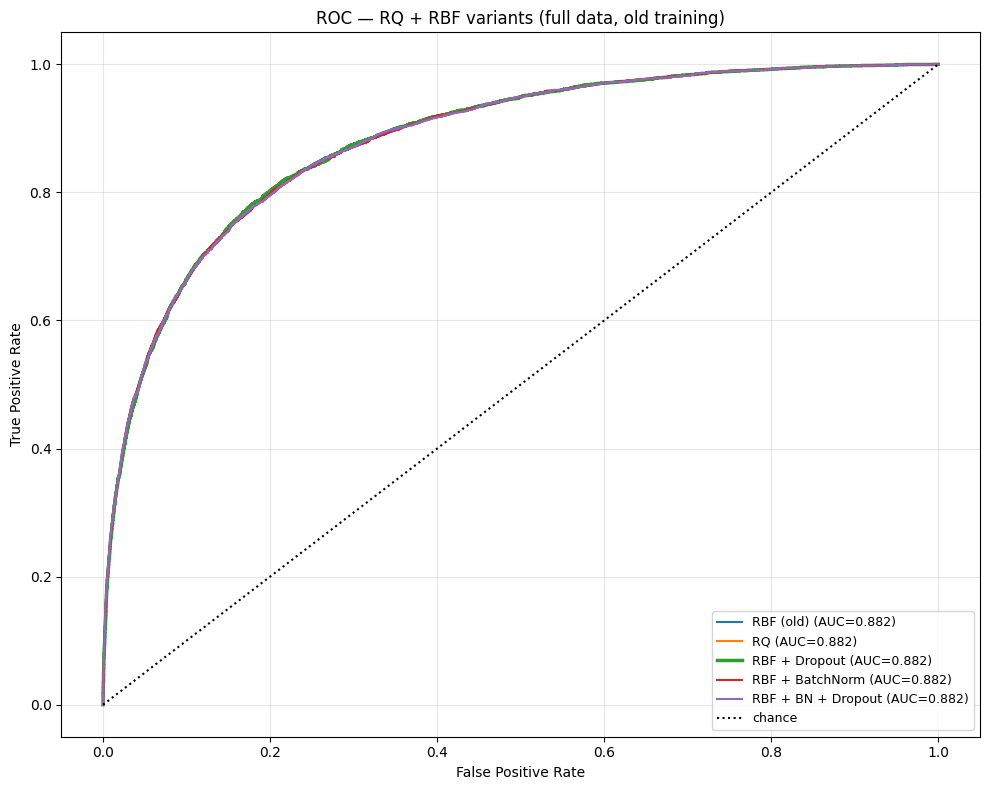

In [6]:
# ====================== RQ + RBF V
# ====================== RQ + RBF VARIANTS — old training setup ======================

import numpy as np
import pandas as pd
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_curve, auc, accuracy_score, f1_score, precision_score, recall_score

print(f"X_train_sc: {X_train_sc.shape}  y_train: {y_train.shape}")
print(f"X_test_sc:  {X_test_sc.shape}  y_test: {y_test.shape}")

n_pos = (y_train == 1).sum()
n_neg = (y_train == 0).sum()
POS_WEIGHT = n_neg / n_pos
print(f"pos_weight = {POS_WEIGHT:.1f}")


def best_threshold_metrics(y_true, scores):
    fpr, tpr, thr_arr = roc_curve(y_true, scores)
    J = tpr - fpr
    idx = int(np.argmax(J))
    thr = thr_arr[idx]
    y_pred = (scores >= thr).astype(int)
    return {
        'best_thr': thr,
        'auc_binary': (1 + tpr[idx] - fpr[idx]) / 2,
        'acc': accuracy_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
        'prec': precision_score(y_true, y_pred),
        'rec': recall_score(y_true, y_pred),
    }


# ====================== LAYERS ======================

class RBFLayer(nn.Module):
    def __init__(self, n_input, n_rbf, X_init):
        super().__init__()
        idx = np.random.RandomState(42).choice(len(X_init), n_rbf, replace=False)
        self.centers = nn.Parameter(torch.FloatTensor(X_init[idx]))
        with torch.no_grad():
            d = torch.cdist(self.centers, self.centers)
            med = d.median().item()
        self.log_sigma = nn.Parameter(torch.ones(n_rbf) * np.log(med / 2 + 1e-8))

    def forward(self, x):
        d2 = torch.cdist(x, self.centers, p=2).pow(2)
        sigma2 = torch.exp(2 * self.log_sigma).unsqueeze(0)
        return torch.exp(-d2 / (2 * sigma2))


class RQLayer(nn.Module):
    def __init__(self, n_input, n_rq, X_init, alpha_init=1.5):
        super().__init__()
        idx = np.random.RandomState(42).choice(len(X_init), n_rq, replace=False)
        self.centers = nn.Parameter(torch.FloatTensor(X_init[idx]))
        with torch.no_grad():
            d = torch.cdist(self.centers, self.centers)
            med = d.median().item()
        self.log_sigma = nn.Parameter(torch.ones(n_rq) * np.log(med / 2 + 1e-8))
        self.log_alpha = nn.Parameter(torch.ones(n_rq) * np.log(alpha_init))

    def forward(self, x):
        d2 = torch.cdist(x, self.centers, p=2).pow(2)
        sigma2 = torch.exp(2 * self.log_sigma).unsqueeze(0)
        alpha = torch.exp(self.log_alpha).unsqueeze(0)
        return (1 + d2 / (2 * alpha * sigma2)).pow(-alpha)


# ====================== MODELS ======================

# 1. RBF (old — baseline)
class RBFNetwork(nn.Module):
    def __init__(self, n_input, n_rbf, X_init):
        super().__init__()
        self.rbf = RBFLayer(n_input, n_rbf, X_init)
        self.output = nn.Linear(n_rbf, 1)

    def forward(self, x):
        return self.output(self.rbf(x)).squeeze(-1)


# 2. RQ (old setup — one variable changed)
class RQNetwork(nn.Module):
    def __init__(self, n_input, n_rq, X_init):
        super().__init__()
        self.rq = RQLayer(n_input, n_rq, X_init)
        self.output = nn.Linear(n_rq, 1)

    def forward(self, x):
        return self.output(self.rq(x)).squeeze(-1)


# 3. RBF + Dropout
class RBFDropout(nn.Module):
    def __init__(self, n_input, n_rbf, X_init, dropout_p=0.3):
        super().__init__()
        self.rbf = RBFLayer(n_input, n_rbf, X_init)
        self.dropout = nn.Dropout(dropout_p)
        self.output = nn.Linear(n_rbf, 1)

    def forward(self, x):
        return self.output(self.dropout(self.rbf(x))).squeeze(-1)


# 4. RBF + BatchNorm
class RBFBatchNorm(nn.Module):
    def __init__(self, n_input, n_rbf, X_init):
        super().__init__()
        self.rbf = RBFLayer(n_input, n_rbf, X_init)
        self.bn = nn.BatchNorm1d(n_rbf)
        self.output = nn.Linear(n_rbf, 1)

    def forward(self, x):
        return self.output(self.bn(self.rbf(x))).squeeze(-1)


# 5. RBF + BatchNorm + Dropout
class RBFBnDropout(nn.Module):
    def __init__(self, n_input, n_rbf, X_init, dropout_p=0.3):
        super().__init__()
        self.rbf = RBFLayer(n_input, n_rbf, X_init)
        self.bn = nn.BatchNorm1d(n_rbf)
        self.dropout = nn.Dropout(dropout_p)
        self.output = nn.Linear(n_rbf, 1)

    def forward(self, x):
        return self.output(self.dropout(self.bn(self.rbf(x)))).squeeze(-1)


# ====================== TRAIN (old setup: 50 epochs, no early stop, no scheduler) ======================

def train_old_style(model, X_tr, y_tr, X_te, y_te,
                    epochs=50, lr=0.001, batch_size=2048):
    torch.manual_seed(42)
    X_tr_t = torch.FloatTensor(X_tr)
    y_tr_t = torch.FloatTensor(y_tr)
    X_te_t = torch.FloatTensor(X_te)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([POS_WEIGHT]))
    train_dl = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=batch_size, shuffle=True)

    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        for Xb, yb in train_dl:
            optimizer.zero_grad()
            loss = criterion(model(Xb), yb)
            loss.backward()
            optimizer.step()
        if (epoch + 1) % 10 == 0:
            print(f"    epoch {epoch+1}: loss={loss.item():.4f}")

    model.eval()
    with torch.no_grad():
        test_scores = torch.sigmoid(model(X_te_t)).numpy()

    elapsed = time.time() - t0

    fpr, tpr, _ = roc_curve(y_te, test_scores)
    auc_prob = auc(fpr, tpr)
    m = best_threshold_metrics(y_te, test_scores)

    print(f"  AUC_prob={auc_prob:.4f}  AUC_bin={m['auc_binary']:.4f}  "
          f"f1={m['f1']:.4f}  time={elapsed:.1f}s")

    return test_scores, auc_prob, m, elapsed


# ====================== TEST 5 CONFIGS ======================

configs = [
    ('RBF (old)',           RBFNetwork(X_train_sc.shape[1], 256, X_train_sc)),
    ('RQ',                  RQNetwork(X_train_sc.shape[1], 256, X_train_sc)),
    ('RBF + Dropout',       RBFDropout(X_train_sc.shape[1], 256, X_train_sc, dropout_p=0.3)),
    ('RBF + BatchNorm',     RBFBatchNorm(X_train_sc.shape[1], 256, X_train_sc)),
    ('RBF + BN + Dropout',  RBFBnDropout(X_train_sc.shape[1], 256, X_train_sc, dropout_p=0.3)),
]

results = []

for name, model in configs:
    print(f"\n{'='*70}")
    print(f"  {name}")
    print(f"{'='*70}")
    scores, auc_prob, m, t = train_old_style(model, X_train_sc, y_train,
                                              X_test_sc, y_test)
    results.append({'model': name, 'auc_prob': auc_prob, 'time': t,
                    'scores': scores, **m})


# ====================== SUMMARY ======================

df_res = pd.DataFrame([{k: v for k, v in r.items() if k != 'scores'}
                        for r in results]).sort_values('auc_binary', ascending=False)

print(f"\n{'='*95}")
print("RQ + RBF VARIANTS — old training, full data (200k)")
print(f"{'='*95}")
print(df_res.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

print(f"\n  GNB reference: AUC_prob=0.8887  AUC_bin=0.8102")


# ====================== PLOTS ======================

plt.figure(figsize=(10, 8))
colors = {
    'RBF (old)': 'tab:blue',
    'RQ': 'tab:orange',
    'RBF + Dropout': 'tab:green',
    'RBF + BatchNorm': 'tab:red',
    'RBF + BN + Dropout': 'tab:purple',
}
for r in results:
    fpr, tpr, _ = roc_curve(y_test, r['scores'])
    lw = 2.5 if r['model'] == df_res.iloc[0]['model'] else 1.5
    plt.plot(fpr, tpr, color=colors[r['model']], lw=lw,
             label=f"{r['model']} (AUC={r['auc_prob']:.3f})")
plt.plot([0, 1], [0, 1], 'k:', label='chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC — RQ + RBF variants (full data, old training)')
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()